<a href="https://colab.research.google.com/github/sidharth463/Capstone-Project--GROUP-14/blob/main/CAPSTONE_(Org).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Transmission Line Signal Integrity

Line parameters
Length = 1.0 m
Number of nodes = 50
dx = 0.02040816326530612 m
R0 = 0.1 ohm/m
L0 = 2.5e-07 H/m
G0 = 0.0 S/m
C0 = 1e-10 F/m
Z0 = 50.0 ohm
Wave velocity = 200000000.0 m/s

Laplace-domain equations
gamma(s) = sqrt((R + L*s)(G + C*s))
Z0(s) = sqrt((R + L*s)/(G + C*s))

Hidden fault
Fault position = 0.4897959183673469 m
Fault nodes = [23 24 25]
Fault resistance = 0.4 ohm/m
Fault capacitance = 6e-11 F/m

FDM stability
dt = 1.020408163265306e-11 s
CFL = 0.09999999999999999
CFL condition is satisfied.
FDM simulation completed.

TDR data created
Noise level = 0.0024315730798507473


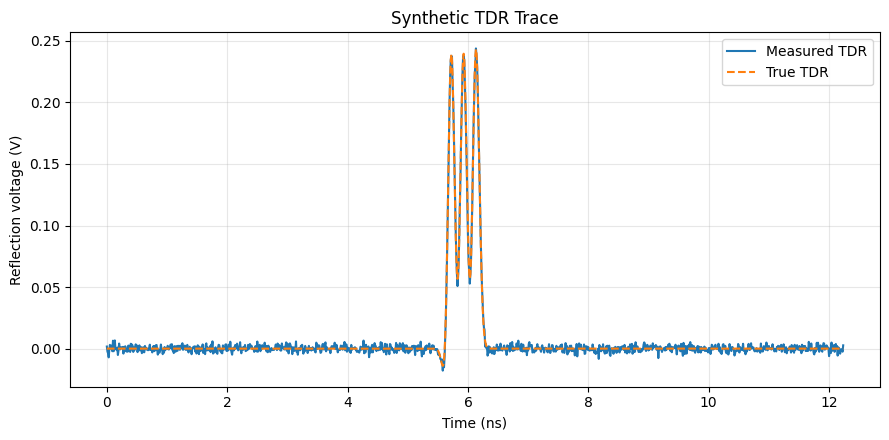


Linear system
A shape = (1200, 96)
b shape = (1200,)

Linear programming
LP success = True
LP message = Optimization terminated successfully. (HiGHS Status 7: Optimal)

Fault reconstruction
True fault = 0.4897959183673469 m
Recovered R fault = 0.4693877551020408 m
Recovered C fault = 0.4693877551020408 m
R fault error = 1 grid cells
C fault error = 1 grid cells


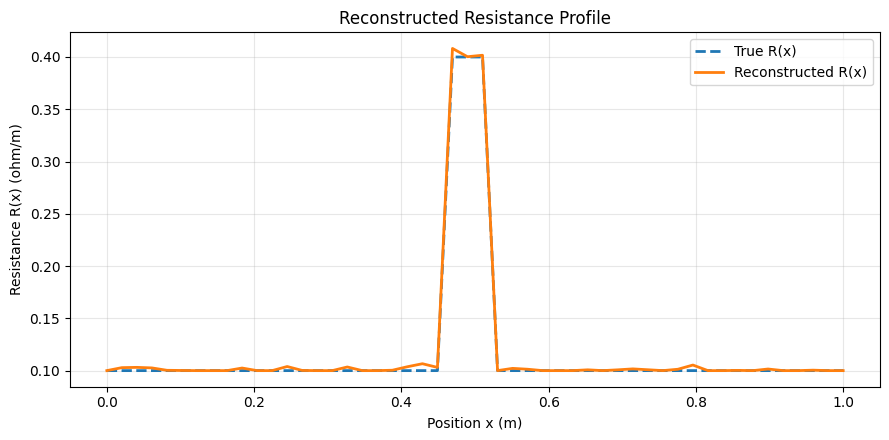

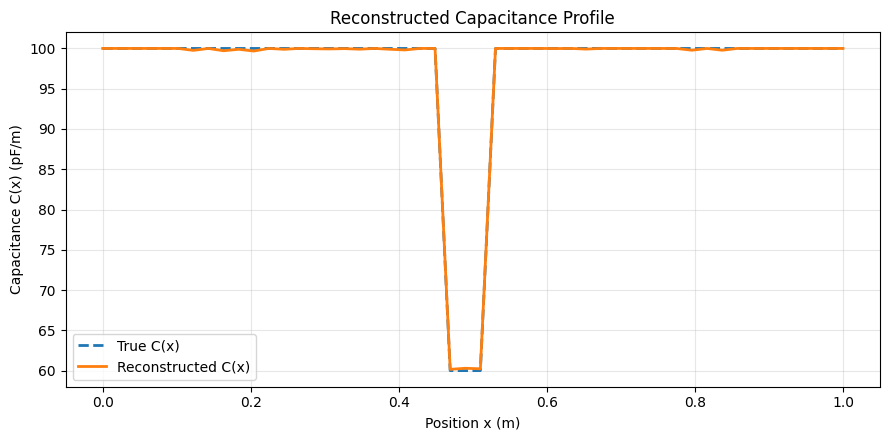

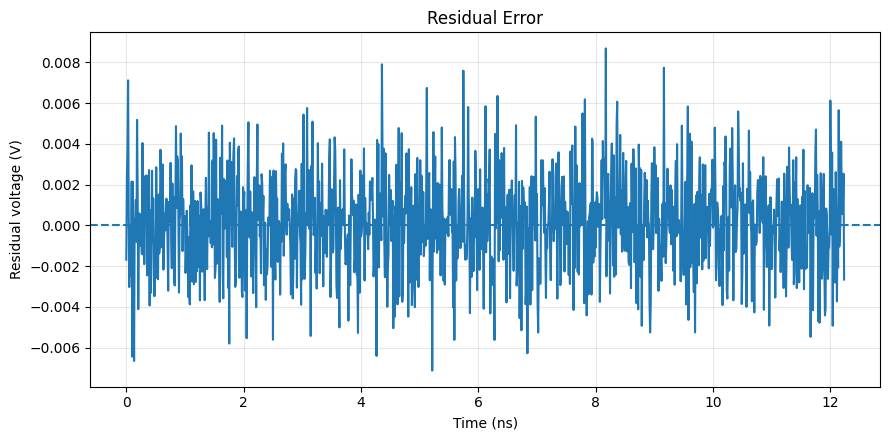


Verification Results
Minimum reconstructed R = 0.1 ohm/m
Minimum reconstructed C = 6.015706068485483e-11 F/m
Maximum absolute residual error = 0.008678852584809162 V


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

print("Transmission Line Signal Integrity")

# TRANSMISSION LINE PARAMETERS

# Define the physical and electrical properties of of the transmission line.
length = 1.0          # length of the transmission line in meters
Nx = 50               # number of spatial nodes
dx = length / (Nx - 1) # distance between adjacent nodes

# Characteristic baseline parameters per unit length
R0 = 0.1              # resistance (ohms per meter)
L0 = 250e-9           # inductance (Henries per meter)
G0 = 0.0              # conductance (Siemens per meter)
C0 = 100e-12          # capacitance (Farads per meter)

# Calculate physical propagation characteristics from L and C
Z0 = np.sqrt(L0 / C0)          # Characteristic impedance (ohms)
velocity = 1 / np.sqrt(L0 * C0) # Wave propagation velocity (meters per second)

# Generate the spatial coordinate array along the line length
x = np.linspace(0, length, Nx)

print("\nLine parameters")
print("Length =", length, "m")
print("Number of nodes =", Nx)
print("dx =", dx, "m")
print("R0 =", R0, "ohm/m")
print("L0 =", L0, "H/m")
print("G0 =", G0, "S/m")
print("C0 =", C0, "F/m")
print("Z0 =", Z0, "ohm")
print("Wave velocity =", velocity, "m/s")


# LAPLACE DOMAIN GOVERNING EQUATIONS

# Reference formulas showing how propagation and impedance depend on frequency (s)
print("\nLaplace-domain equations")
print("gamma(s) = sqrt((R + L*s)(G + C*s))")
print("Z0(s) = sqrt((R + L*s)/(G + C*s))")


# CREATING A HIDDEN FAULT

# Initialize spatial arrays with baseline properties
R_true = np.full(Nx, R0)
C_true = np.full(Nx, C0)

# Define a localized structural fault at the midpoint of the line
fault_position = 0.5
fault_node = np.argmin(np.abs(x - fault_position))

# Apply the physical fault over a narrow region
fault_nodes = np.arange(fault_node - 1, fault_node + 2)

# Modify local parameters: increase resistance and decrease capacitance at the fault location
R_true[fault_nodes] = 4 * R0
C_true[fault_nodes] = 0.6 * C0

print("\nHidden fault")
print("Fault position =", x[fault_node], "m")
print("Fault nodes =", fault_nodes)
print("Fault resistance =", 4 * R0, "ohm/m")
print("Fault capacitance =", 0.6 * C0, "F/m")


# FINITE DIFFERENCE METHOD (FDM) & STABILITY CRITERION

# Define time step and total steps, ensuring we satisfy the Courant-Friedrichs-Lewy (CFL) condition for stability
dt = 0.10 * dx / velocity # Time step size (seconds)
n_steps = 1200             # Total simulation steps
CFL = velocity * dt / dx  # CFL value

print("\nFDM stability")
print("dt =", dt, "s")
print("CFL =", CFL)

if CFL < 1:
    print("CFL condition is satisfied.")
else:
    print("CFL condition is NOT satisfied.")


# FDM FORWARD SOLVER
# Solves the 1D telegrapher's partial differential equations over time
def fdm_forward_solver(R_profile, C_profile):
    t = np.arange(n_steps) * dt
    V = np.zeros(Nx)       # Node voltages
    I = np.zeros(Nx - 1)   # Branch currents between nodes

    voltage_input = np.zeros(n_steps)  # Voltage tracked at the source end
    voltage_output = np.zeros(n_steps) # Voltage tracked at the load end

    # Precompute averaged resistance at half-grid points for the current update
    R_half = 0.5 * (R_profile[:-1] + R_profile[1:])

    for n in range(n_steps):
        # Update Current: Compute spatial derivative of voltage and step current forward
        dVdx = (V[1:] - V[:-1]) / dx
        I += (dt / L0) * (-dVdx - R_half * I)

        # Update Voltage: Compute spatial derivative of current and step internal node voltages forward
        dIdx = np.zeros(Nx)
        dIdx[1:-1] = (I[1:] - I[:-1]) / dx
        V[1:-1] += (dt / C_profile[1:-1]) * (-dIdx[1:-1] - G0 * V[1:-1])

        #  Source Excitation: Generate an ultra-fast Gaussian input pulse
        source = np.exp(-((t[n] - 1e-9) / 0.25e-9) ** 2)

        # Apply Boundary Conditions: Source matched termination boundary
        V[0] = source - Z0 * I[0]

        # Load matched termination boundary
        V[-1] = Z0 * I[-1]

        # Record terminal voltages for analysis
        voltage_input[n] = V[0]
        voltage_output[n] = V[-1]

    return t, voltage_input, voltage_output

# Execute the FDM simulator using the true faulty transmission line profile
t, fdm_input, fdm_output = fdm_forward_solver(R_true, C_true)
print("FDM simulation completed.")


# TIME-DOMAIN REFLECTOMETRY (TDR) SENSITIVITY MATRIX CONSTRUCTION

# Construct linear sensitivity matrices (dictionaries of reflection signatures)
# mapping localized parameter variations to deviations in the measured TDR response.
t0 = 1e-9
sigma = 0.06e-9

A_R = np.zeros((n_steps, Nx)) # Sensitivity matrix for resistance changes
A_C = np.zeros((n_steps, Nx)) # Sensitivity matrix for capacitance changes

for j in range(1, Nx - 1):
    # Calculate the round-trip propagation time delay to node j and back
    delay = t0 + 2 * x[j] / velocity

    # Normalized time vector centered around the reflection arrival time
    z = (t - delay) / sigma

    # Gaussian profile representing the shape of the reflected wave
    gaussian = np.exp(-0.5 * z ** 2)

    # Sensitivity coefficients derived from the derivative of the reflection response
    A_R[:, j] = 0.5 * z * gaussian
    A_C[:, j] = 0.5 * gaussian

# Define the true perturbation profiles
delta_R_true = R_true - R0
delta_C_true = (C0 - C_true) / C0

# Perform linear forward projection to synthesize the clean TDR trace
tdr_true = A_R @ delta_R_true + A_C @ delta_C_true

# Add realistic measurement noise to the synthesized trace
rng = np.random.default_rng(14)
noise_level = 0.01 * np.max(np.abs(tdr_true))
noise = rng.normal(0, noise_level, n_steps)
tdr_measured = tdr_true + noise

print("\nTDR data created")
print("Noise level =", noise_level)


# VISUALIZE SYNTHETIC TDR DATA

plt.figure(figsize=(9, 4.5))
plt.plot(t * 1e9, tdr_measured, label="Measured TDR")
plt.plot(t * 1e9, tdr_true, "--", label="True TDR")
plt.xlabel("Time (ns)")
plt.ylabel("Reflection voltage (V)")
plt.title("Synthetic TDR Trace")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("tdr.png", dpi=300, bbox_inches="tight")
plt.show()


# LINEAR PROGRAMMING (LP)

# Exclude boundaries and focus only on the internal line segments
active = np.arange(1, Nx - 1)

# Stack resistance and capacitance sensitivity columns to form the system matrix A
A = np.hstack((A_R[:, active], A_C[:, active]))
b = tdr_measured

print("\nLinear system")
print("A shape =", A.shape)
print("b shape =", b.shape)

m = A.shape[0]
n = A.shape[1]

# Objective function: Minimize l1-norm of the residual + regularize parameter magnitudes
objective = np.concatenate((0.0001 * np.ones(n), np.ones(m)))

# Formulate LP inequality constraints (A_ub * x <= b_ub) to represent absolute values
A_ub = np.zeros((2 * m, n + m))
b_ub = np.zeros(2 * m)

# First half of inequalities: Ax - u <= b
A_ub[:m, :n] = A
A_ub[:m, n:] = -np.eye(m)
b_ub[:m] = b

# Second half of inequalities: -Ax - u <= -b
A_ub[m:, :n] = -A
A_ub[m:, n:] = -np.eye(m)
b_ub[m:] = -b

# Define bounds on optimization variables
bounds = [(0, None)] * (n + m)

# Solve the optimization problem using the high-performance HiGHS solver
result = linprog(
    objective,
    A_ub=A_ub,
    b_ub=b_ub,
    bounds=bounds,
    method="highs"
)

print("\nLinear programming")
print("LP success =", result.success)
print("LP message =", result.message)

if not result.success:
    raise RuntimeError("Linear programming failed.")


# CONSTRUCT PHYSICAL MODEL FROM LP OPTIMIZATION RESULTS

solution = result.x
parameter_solution = solution[:n]
number_active = len(active)

delta_R_reconstructed = parameter_solution[:number_active]
delta_C_reconstructed = parameter_solution[number_active:]

R_reconstructed = np.full(Nx, R0)
C_reconstructed = np.full(Nx, C0)

R_reconstructed[active] = R0 + delta_R_reconstructed
C_reconstructed[active] = C0 * (1 - delta_C_reconstructed)

R_reconstructed = np.maximum(R_reconstructed, 0)
C_reconstructed = np.maximum(C_reconstructed, 0)

R_fault_node = np.argmax(R_reconstructed)
C_fault_node = np.argmin(C_reconstructed)

R_fault_position = x[R_fault_node]
C_fault_position = x[C_fault_node]


R_grid_error = abs(R_fault_node - fault_node)
C_grid_error = abs(C_fault_node - fault_node)

print("\nFault reconstruction")
print("True fault =", x[fault_node], "m")
print("Recovered R fault =", R_fault_position, "m")
print("Recovered C fault =", C_fault_position, "m")
print("R fault error =", R_grid_error, "grid cells")
print("C fault error =", C_grid_error, "grid cells")


# 10. PLOT RECONSTRUCTED PARAMETER PROFILES VS. GROUND TRUTH

# Reconstructed Resistance Profile
plt.figure(figsize=(9, 4.5))
plt.plot(x, R_true, "--", linewidth=2, label="True R(x)")
plt.plot(x, R_reconstructed, linewidth=2, label="Reconstructed R(x)")
plt.xlabel("Position x (m)")
plt.ylabel("Resistance R(x) (ohm/m)")
plt.title("Reconstructed Resistance Profile")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("R_reconstruction.png", dpi=300, bbox_inches="tight")
plt.show()

# Reconstructed Capacitance Profile
plt.figure(figsize=(9, 4.5))
plt.plot(x, C_true * 1e12, "--", linewidth=2, label="True C(x)")
plt.plot(x, C_reconstructed * 1e12, linewidth=2, label="Reconstructed C(x)")
plt.xlabel("Position x (m)")
plt.ylabel("Capacitance C(x) (pF/m)")
plt.title("Reconstructed Capacitance Profile")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("C_reconstruction.png", dpi=300, bbox_inches="tight")
plt.show()


# RESIDUAL ERROR ANALYSIS

# Calculate the error between our optimized model's prediction and actual observations
predicted = A @ parameter_solution
residual = predicted - b
maximum_residual = np.max(np.abs(residual))

plt.figure(figsize=(9, 4.5))
plt.plot(t * 1e9, residual)
plt.axhline(0, linestyle="--")
plt.xlabel("Time (ns)")
plt.ylabel("Residual voltage (V)")
plt.title("Residual Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("residual.png", dpi=300, bbox_inches="tight")
plt.show()



print("\nVerification Results")
print("Minimum reconstructed R =", np.min(R_reconstructed), "ohm/m")
print("Minimum reconstructed C =", np.min(C_reconstructed), "F/m")
print("Maximum absolute residual error =", maximum_residual, "V")
